<a href="https://colab.research.google.com/github/jayavenkatasai224/ITA0514-Computer-Vision/blob/main/ex_no_25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload 1. Template Image
Upload 2. Input Image


Saving Analysis output 1.png to Analysis output 1 (2).png
Saving Analysis output 2.png to Analysis output 2 (1).png
Watch Recognized
Matching Score: 0.62
Object Recognition Output


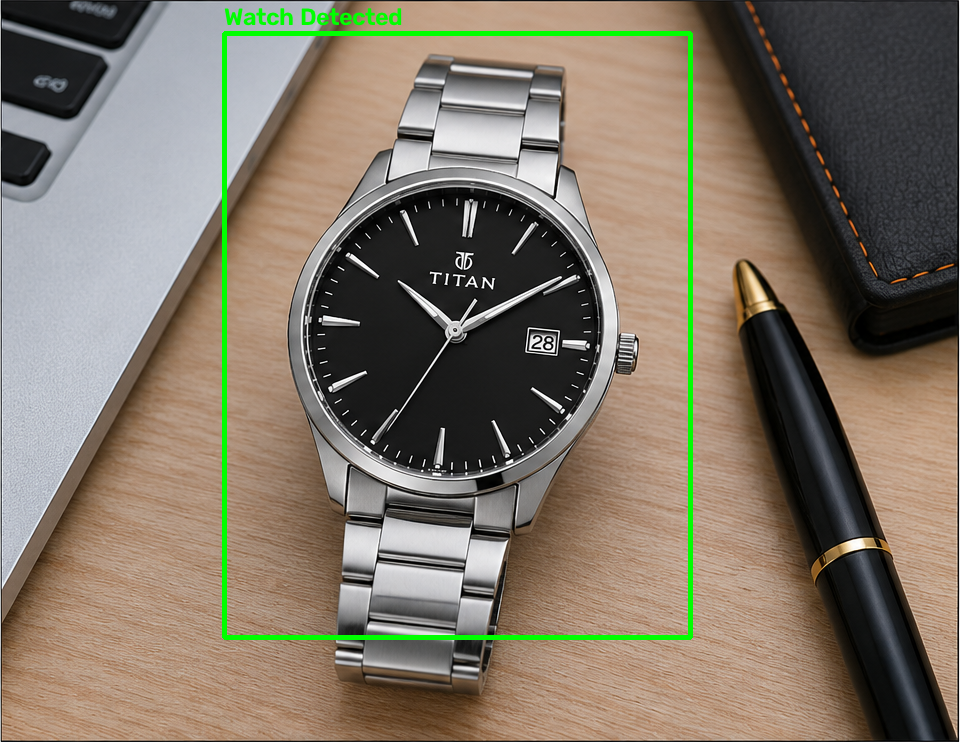

In [30]:

import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow

# Upload two images
print("Upload 1. Template Image")
print("Upload 2. Input Image")

uploaded = files.upload()

# Get uploaded filenames
filenames = list(uploaded.keys())

if len(filenames) != 2:
    print("Please upload exactly two images")
else:
    # Read template and input images
    template = cv2.imread(filenames[0])
    img = cv2.imread(filenames[1])

    if template is None or img is None:
        print("Error reading images")
    else:
        # Convert images to grayscale
        template_gray = cv2.cvtColor(
            template, cv2.COLOR_BGR2GRAY
        )
        gray = cv2.cvtColor(
            img, cv2.COLOR_BGR2GRAY
        )

        # Get template dimensions
        h, w = template_gray.shape

        best_score = -1
        best_location = None
        best_size = None

        # Multi-scale template matching
        for scale in np.linspace(0.5, 1.5, 30):
            new_w = int(w * scale)
            new_h = int(h * scale)

            if new_w > gray.shape[1] or new_h > gray.shape[0]:
                continue

            resized = cv2.resize(
                template_gray, (new_w, new_h)
            )

            result = cv2.matchTemplate(
                gray, resized, cv2.TM_CCOEFF_NORMED
            )

            _, max_val, _, max_loc = cv2.minMaxLoc(result)

            if max_val > best_score:
                best_score = max_val
                best_location = max_loc
                best_size = (new_w, new_h)

        # Detect watch
        if best_score >= 0.50:
            x, y = best_location
            new_w, new_h = best_size

            cv2.rectangle(
                img,
                (x, y),
                (x + new_w, y + new_h),
                (0, 255, 0),
                3
            )

            cv2.putText(
                img,
                "Watch Detected",
                (x, max(25, y - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.8,
                (0, 255, 0),
                2
            )

            print("Watch Recognized")
            print("Matching Score:", round(best_score, 2))
        else:
            print("Watch Not Recognized")

        # Display output
        print("Object Recognition Output")
        cv2_imshow(img)
